# 🐼📈 Pandas і графіки для аналітиків · Блокнот 2 з 7
## Вибір, фільтрація та сортування · 📈 Налаштовуємо вигляд графіка

У реальній таблиці тисячі рядків і десятки стовпців, але для конкретного питання потрібна лише частина. «Покажи замовлення зі Львова», «які товари отримали оцінку 1», «топ-5 найбільших замовлень»: усе це **вибір і фільтрація**.

### У цьому блокноті ви навчитеся
1. Обирати потрібні **стовпці**.
2. Обирати **рядки** за номером: `iloc` і `loc`.
3. **Фільтрувати** рядки за умовами, як фільтр в Excel.
4. **Сортувати** таблицю і знаходити «топ-N».
5. 📈 **Налаштовувати графік**: горизонтальні стовпчики, розмір, колір, підписи значень, виділення головного.
6. 📈 Задавати **єдиний стиль** для всіх графіків і зберігати графік у файл.

### Як працювати з блокнотом
- Запускайте клітинки **по черзі зверху вниз**: кнопка ▶ ліворуч або **`Shift + Enter`**.
- **Першою** запустіть клітинку «📦 Підготовка даних»: вона створить файли з даними.
- Змінюйте числа й умови в прикладах і дивіться, що вийде. Зламати нічого не можна.
- У практиці пишіть код у клітинках «Ваш код тут». Розв'язки всіх завдань зібрані в **останній клітинці** блокнота. Спершу спробуйте самостійно, а туди зазирайте, лише якщо справді застрягли.
- Розділи з позначкою **📈** — про графіки. Вони йдуть паралельно з pandas і поступово ускладнюються від блокнота до блокнота.

<details>
<summary><b>📚 Увесь курс</b></summary>

01. Знайомство з pandas · 📈 Перший графік<br>**02. Вибір, фільтрація та сортування · 📈 Налаштовуємо вигляд графіка** ← ви тут<br>03. Нові стовпці та очищення даних · 📈 Графіки для перевірки даних<br>04. Групування та зведені таблиці · 📈 Графіки з групувань<br>05. Об'єднання таблиць · 📈 Порівняння і зв'язки<br>06. Робота з датами · 📈 Графіки динаміки<br>07. Фінальний проєкт · 📈 Дашборд для керівника

</details>

## Крок 0. Готуємо дані

In [2]:
# @title 📦 Підготовка даних — просто запустіть цю клітинку (Shift + Enter)
# Ця клітинка створює навчальні файли з даними інтернет-магазину за 2025 рік.
# Розбиратися в її коді не потрібно.
# Якщо Colab перезапустився і файли зникли — просто запустіть її ще раз.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(2025)

# ---------- Товари ----------
products = pd.DataFrame([
    ("P01", "Headphones",         "Electronics", 1500,  900),
    ("P02", "Power bank",         "Electronics",  900,  520),
    ("P03", "Smartwatch",    "Electronics", 4200, 2900),
    ("P04", "Bluetooth speaker", "Electronics", 2100, 1300),
    ("P05", "T-shirt",          "Clothing",         450,  180),
    ("P06", "Hoodie",              "Clothing",        1200,  550),
    ("P07", "Jeans",            "Clothing",        1600,  800),
    ("P08", "Sneakers",          "Clothing",        2800, 1600),
    ("P09", "Mug",             "Home",          180,   60),
    ("P10", "Blanket",              "Home",          850,  400),
    ("P11", "Desk lamp",   "Home",         1100,  600),
    ("P12", "Towel set",    "Home",          650,  300),
    ("P13", "Face cream",  "Beauty",        520,  210),
    ("P14", "Shampoo",           "Beauty",        260,  110),
    ("P15", "Perfume",           "Beauty",       2400, 1300),
    ("P16", "Yoga mat",  "Sports",        700,  320),
    ("P17", "Water bottle",   "Sports",        350,  140),
    ("P18", "Dumbbells 5 kg",      "Sports",        950,  550),
], columns=["product_id", "product", "category", "price", "cost"])

# ---------- Клієнти ----------
n_cust = 400
names = ["Olena", "Andrii", "Mariia", "Ihor", "Nataliia", "Dmytro", "Iryna", "Oleksandr",
         "Tetiana", "Serhii", "Yuliia", "Maksym", "Oksana", "Viktor", "Anna", "Bohdan",
         "Kateryna", "Taras", "Sofiia", "Roman"]
cities = ["Kyiv", "Lviv", "Odesa", "Kharkiv", "Dnipro"]
reg = pd.Timestamp("2022-01-01") + pd.to_timedelta(rng.integers(0, 3 * 365, n_cust), unit="D")
customers = pd.DataFrame({
    "customer_id": [f"C{i:04d}" for i in range(1, n_cust + 1)],
    "name": rng.choice(names, n_cust),
    "city": rng.choice(cities, n_cust, p=[0.35, 0.2, 0.15, 0.15, 0.15]),
    "age": np.clip(rng.normal(33, 9, n_cust).round(), 18, 65).astype(int),
    "registration_date": reg.strftime("%Y-%m-%d"),
})

# ---------- Замовлення ----------
n = 3000
days = pd.date_range("2025-01-01", "2025-12-31")
w = np.linspace(0.85, 1.15, len(days))          # магазин поступово росте
w[days.month.isin([6, 7, 8])] *= 0.8            # влітку спокійніше
w[days.month.isin([11, 12])] *= 1.5             # сезон розпродажів і свят
w[days.dayofweek >= 5] *= 1.3                   # у вихідні купують більше
w[days == pd.Timestamp("2025-11-28")] *= 6      # Чорна п'ятниця
order_date = pd.DatetimeIndex(np.sort(rng.choice(days.values, n, p=w / w.sum())))

cust_w = rng.gamma(1.0, 1, n_cust)
cust_idx = rng.choice(n_cust, n, p=cust_w / cust_w.sum())
prod_w = 1 / np.sqrt(products["price"].to_numpy())
prod_idx = rng.choice(len(products), n, p=prod_w / prod_w.sum())

quantity = rng.choice([1, 2, 3, 4], n, p=[0.72, 0.18, 0.07, 0.03])
payment = rng.choice(["Card", "Cash on delivery", "Google/Apple Pay"], n, p=[0.55, 0.27, 0.18])
channel = rng.choice(["Website", "App", "Instagram"], n, p=[0.5, 0.35, 0.15])

cod = payment == "Cash on delivery"
u = rng.random(n)
status = np.where(u < np.where(cod, 0.80, 0.91), "Delivered",
                  np.where(u < np.where(cod, 0.92, 0.96), "Cancelled", "Returned"))

city = customers["city"].to_numpy()[cust_idx]
deliv_days = np.where(city == "Kyiv", rng.integers(1, 3, n), rng.integers(1, 6, n))
delivery = order_date + pd.to_timedelta(deliv_days, unit="D")
delivery_str = np.where(status == "Cancelled", None, delivery.strftime("%Y-%m-%d"))

rating = np.where(deliv_days >= 4,
                  rng.choice(5, n, p=[0.08, 0.12, 0.22, 0.33, 0.25]) + 1,
                  rng.choice(5, n, p=[0.03, 0.05, 0.12, 0.35, 0.45]) + 1).astype(float)
returned = status == "Returned"
rating[returned] = rng.choice([1, 2, 3], returned.sum(), p=[0.5, 0.3, 0.2])
rating[(status == "Cancelled") | (rng.random(n) > 0.6)] = np.nan

orders = pd.DataFrame({
    "order_id": np.arange(100001, 100001 + n),
    "order_date": order_date.strftime("%Y-%m-%d"),
    "delivery_date": delivery_str,
    "customer_id": customers["customer_id"].to_numpy()[cust_idx],
    "product_id": products["product_id"].to_numpy()[prod_idx],
    "quantity": quantity,
    "payment": payment,
    "channel": channel,
    "status": status,
    "rating": rating,
})

# ---------- Одна велика таблиця продажів ----------
sales = (orders.merge(customers[["customer_id", "city"]], on="customer_id", how="left")
               .merge(products[["product_id", "product", "category", "price"]], on="product_id", how="left"))
sales = sales[["order_id", "order_date", "delivery_date", "customer_id", "city", "category",
               "product", "price", "quantity", "payment", "channel", "status", "rating"]]
sales = sales.sort_values("order_id").reset_index(drop=True)

# ---------- Квартальні вивантаження ----------
quarter = pd.to_datetime(sales["order_date"]).dt.quarter
for q in range(1, 5):
    sales[quarter == q].to_csv(f"sales_2025_Q{q}.csv", index=False)

# ---------- «Брудне» вивантаження продажів ----------
raw = sales.copy()
raw["price"] = raw["price"].astype(str) + " UAH"
raw["order_date"] = pd.to_datetime(raw["order_date"]).dt.strftime("%d.%m.%Y")
raw["delivery_date"] = pd.to_datetime(raw["delivery_date"]).dt.strftime("%d.%m.%Y")
messy = {"Kyiv": ["kyiv", "KYIV", " Kyiv", "Kiev"], "Lviv": ["lviv", "Lviv ", " LVIV"],
         "Odesa": ["odesa", "Odesa "], "Kharkiv": ["kharkiv", "KHARKIV "], "Dnipro": ["dnipro", " Dnipro"]}
city_col = raw["city"].to_numpy(dtype=object)
for i in rng.choice(n, 300, replace=False):
    city_col[i] = rng.choice(messy[city_col[i]])
city_col[rng.choice(n, 15, replace=False)] = None
raw["city"] = city_col
qty_col = raw["quantity"].to_numpy(dtype=float)
qty_col[rng.choice(n, 40, replace=False)] = np.nan
raw["quantity"] = qty_col
pay_col = raw["payment"].to_numpy(dtype=object)
pay_col[rng.choice(n, 60, replace=False)] = None
raw["payment"] = pay_col
raw = pd.concat([raw, raw.iloc[rng.choice(n, 25, replace=False)]])
raw = raw.sort_values("order_id", kind="stable").reset_index(drop=True)
raw.columns = ["Order ID", "Order Date", "Delivery Date", "Customer ID", "City", "Category",
               "Product", "Price", "Qty", "Payment", "Channel", "Status", "Rating"]

# ---------- «Брудний» список клієнтів ----------
craw = customers.copy()
name_col = craw["name"].to_numpy(dtype=object)
for i in rng.choice(n_cust, 40, replace=False):
    name_col[i] = rng.choice([name_col[i].lower(), name_col[i].upper(), " " + name_col[i] + " "])
craw["name"] = name_col
cc = craw["city"].to_numpy(dtype=object)
for i in rng.choice(n_cust, 50, replace=False):
    cc[i] = rng.choice([cc[i].lower(), cc[i].upper(), cc[i] + " "])
craw["city"] = cc
age_col = craw["age"].to_numpy(dtype=float)
age_col[rng.choice(n_cust, 12, replace=False)] = np.nan
craw["age"] = age_col
craw["registration_date"] = pd.to_datetime(craw["registration_date"]).dt.strftime("%d/%m/%Y")
craw = pd.concat([craw, craw.iloc[rng.choice(n_cust, 8, replace=False)]])
craw = craw.sort_values("customer_id", kind="stable").reset_index(drop=True)

# ---------- Зберігаємо файли ----------
sales.to_csv("sales.csv", index=False)
orders.to_csv("orders.csv", index=False)
customers.to_csv("customers.csv", index=False)
products.to_csv("products.csv", index=False)
raw.to_csv("sales_raw.csv", index=False)
craw.to_csv("customers_raw.csv", index=False)

# ---------- Налаштування вигляду таблиць ----------
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}".replace(",", " "))

del (rng, names, cities, reg, n, n_cust, days, w, order_date, cust_w, cust_idx, prod_w, prod_idx,
     quantity, payment, channel, cod, u, status, city, deliv_days, delivery, delivery_str, rating,
     returned, quarter, q, raw, messy, city_col, qty_col, pay_col, craw, name_col, cc, age_col, i,
     sales, orders, customers, products)

print("✅ Done! Data files created:")
print("   sales.csv, orders.csv, customers.csv, products.csv,")
print("   sales_raw.csv, customers_raw.csv, sales_2025_Q1…Q4.csv")

✅ Done! Data files created:
   sales.csv, orders.csv, customers.csv, products.csv,
   sales_raw.csv, customers_raw.csv, sales_2025_Q1…Q4.csv


In [3]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("sales.csv")
df.head()

,order_id,order_date,delivery_date,customer_id,city,category,product,price,quantity,payment,channel,status,rating
0,100001,2025-01-01,NaN,C0230,Kyiv,Sports,Dumbbells 5 kg,950,4,Card,Website,Cancelled,NaN
1,100002,2025-01-01,2025-01-02,C0074,Odesa,Electronics,Smartwatch,4200,3,Google/Apple Pay,Website,Delivered,5.00
2,100003,2025-01-01,2025-01-05,C0216,Odesa,Electronics,Smartwatch,4200,1,Google/Apple Pay,Website,Delivered,NaN
3,100004,2025-01-01,2025-01-02,C0219,Kyiv,Electronics,Bluetooth speaker,2100,1,Cash on delivery,Instagram,Delivered,5.00
4,100005,2025-01-01,2025-01-06,C0026,Lviv,Home,Desk lamp,1100,1,Card,App,Delivered,4.00


<details>
<summary><b>Нагадування: що означають стовпці</b> (натисніть, щоб розгорнути)</summary>


| Стовпець | Що означає |
|---|---|
| `order_id` | номер замовлення |
| `order_date` | дата замовлення |
| `delivery_date` | дата доставки (порожньо, якщо замовлення скасували) |
| `customer_id` | код клієнта |
| `city` | місто клієнта |
| `category` | категорія товару |
| `product` | назва товару |
| `price` | ціна за одиницю, грн |
| `quantity` | кількість одиниць у замовленні |
| `payment` | спосіб оплати: `Card`, `Cash on delivery` (накладений платіж), `Google/Apple Pay` |
| `channel` | звідки прийшло замовлення: `Website`, `App`, `Instagram` |
| `status` | `Delivered` / `Cancelled` / `Returned` (доставлено / скасовано / повернено) |
| `rating` | оцінка клієнта від 1 до 5 (порожньо, якщо клієнт не оцінив) |

</details>

---
## Крок 1. Вибір стовпців

### Один стовпець: одні квадратні дужки
Результат — **Series** (один стовпець).

In [ ]:
df["product"]

,product
0,Dumbbells 5 kg
1,Smartwatch
2,Smartwatch
3,Bluetooth speaker
4,Desk lamp
...,...
2995,Face cream
2996,Dumbbells 5 kg
2997,Water bottle
2998,Yoga mat


### Кілька стовпців: подвійні квадратні дужки
Зовнішні дужки означають «вибери з таблиці», внутрішні — це **список** назв стовпців. Результат — нова **таблиця**.

In [ ]:
df[["order_id", "product", "price", "quantity"]]

,order_id,product,price,quantity
0,100001,Dumbbells 5 kg,950,4
1,100002,Smartwatch,4200,3
2,100003,Smartwatch,4200,1
3,100004,Bluetooth speaker,2100,1
4,100005,Desk lamp,1100,1
...,...,...,...,...
2995,102996,Face cream,520,1
2996,102997,Dumbbells 5 kg,950,1
2997,102998,Water bottle,350,1
2998,102999,Yoga mat,700,1


⚠️ **Найчастіша помилка новачків:** `df["product", "price"]` (одні дужки для кількох стовпців) дасть помилку `KeyError`. Для кількох стовпців потрібні **подвійні** дужки.

💡 Список стовпців можна зберегти в змінну. Це зручно, коли той самий набір потрібен багато разів:

In [ ]:
short_view = ["order_id", "order_date", "city", "product", "price"]

df[short_view].head(3)

,order_id,order_date,city,product,price
0,100001,2025-01-01,Kyiv,Dumbbells 5 kg,950
1,100002,2025-01-01,Odesa,Smartwatch,4200
2,100003,2025-01-01,Odesa,Smartwatch,4200


---
## Крок 2. Вибір рядків за номером: `iloc` і `loc`

| | `iloc` | `loc` |
|---|---|---|
| Як обирає | за **позицією** (як у NumPy) | за **назвою** рядка і стовпця |
| Зріз `0:5` | рядки 0, 1, 2, 3, 4 (5 **не** входить) | рядки 0, 1, 2, 3, 4, **5** (кінець входить) |
| Як запам'ятати | **i** = integer (ціле число, номер) | **l** = label (підпис, назва) |

In [ ]:
df.iloc[0]          # перший рядок (показується «боком», як Series)

,0
order_id,100001
order_date,2025-01-01
delivery_date,NaN
customer_id,C0230
city,Kyiv
category,Sports
product,Dumbbells 5 kg
price,950
quantity,4
payment,Card


In [ ]:
df.iloc[0:3]        # рядки з позиціями 0, 1, 2

,order_id,order_date,delivery_date,customer_id,city,category,product,price,quantity,payment,channel,status,rating
0,100001,2025-01-01,NaN,C0230,Kyiv,Sports,Dumbbells 5 kg,950,4,Card,Website,Cancelled,NaN
1,100002,2025-01-01,2025-01-02,C0074,Odesa,Electronics,Smartwatch,4200,3,Google/Apple Pay,Website,Delivered,5.00
2,100003,2025-01-01,2025-01-05,C0216,Odesa,Electronics,Smartwatch,4200,1,Google/Apple Pay,Website,Delivered,NaN


In [ ]:
df.iloc[0:3, 0:4]   # рядки 0–2 і стовпці 0–3: [рядки, стовпці]

,order_id,order_date,delivery_date,customer_id
0,100001,2025-01-01,NaN,C0230
1,100002,2025-01-01,2025-01-02,C0074
2,100003,2025-01-01,2025-01-05,C0216


`loc` зручніший, коли ви знаєте **назви стовпців**:

In [ ]:
df.loc[0:4, ["product", "price", "quantity"]]   # рядки з індексом 0..4 (4 включно!)

,product,price,quantity
0,Dumbbells 5 kg,950,4
1,Smartwatch,4200,3
2,Smartwatch,4200,1
3,Bluetooth speaker,2100,1
4,Desk lamp,1100,1


💡 На практиці рядки рідко обирають за номером, частіше **за умовою**. Цим і займемося далі.

---
## Крок 3. Фільтрація: відбираємо рядки за умовою

### 3.1 Як це працює всередині
Фільтр — це два кроки:
1. Порівняння стовпця з чимось дає **маску**: стовпець з `True` (підходить) і `False` (не підходить).
2. Маску підставляємо в квадратні дужки, і лишаються тільки рядки з `True`.

In [ ]:
mask = df["city"] == "Lviv"      # == означає «дорівнює» (одне = — це присвоєння!)
mask.head(10)

,city
0,False
1,False
2,False
3,False
4,True
5,False
6,False
7,False
8,False
9,False


In [ ]:
lviv = df[mask]
lviv.head()

,order_id,order_date,delivery_date,customer_id,city,category,product,price,quantity,payment,channel,status,rating
4,100005,2025-01-01,2025-01-06,C0026,Lviv,Home,Desk lamp,1100,1,Card,App,Delivered,4.00
12,100013,2025-01-02,2025-01-04,C0161,Lviv,Home,Towel set,650,1,Card,App,Delivered,5.00
13,100014,2025-01-02,2025-01-03,C0307,Lviv,Electronics,Bluetooth speaker,2100,1,Card,Website,Delivered,5.00
16,100017,2025-01-03,2025-01-07,C0242,Lviv,Electronics,Power bank,900,1,Google/Apple Pay,Website,Delivered,NaN
17,100018,2025-01-03,2025-01-05,C0155,Lviv,Home,Desk lamp,1100,2,Google/Apple Pay,Instagram,Delivered,5.00


Зазвичай обидва кроки пишуть в одному рядку:

In [ ]:
lviv = df[df["city"] == "Lviv"]

print("Orders from Lviv:", len(lviv))     # len() — кількість рядків

Orders from Lviv: 678


### 3.2 Оператори порівняння

| Оператор | Значення | Приклад |
|---|---|---|
| `==` | дорівнює | `df["status"] == "Cancelled"` |
| `!=` | не дорівнює | `df["channel"] != "Website"` |
| `>` / `<` | більше / менше | `df["price"] > 2000` |
| `>=` / `<=` | більше або дорівнює / менше або дорівнює | `df["quantity"] >= 2` |

In [ ]:
expensive = df[df["price"] > 2000]
print("Orders with items above 2,000 UAH:", len(expensive))
expensive.head()

Orders with items above 2,000 UAH: 385


,order_id,order_date,delivery_date,customer_id,city,category,product,price,quantity,payment,channel,status,rating
1,100002,2025-01-01,2025-01-02,C0074,Odesa,Electronics,Smartwatch,4200,3,Google/Apple Pay,Website,Delivered,5.00
2,100003,2025-01-01,2025-01-05,C0216,Odesa,Electronics,Smartwatch,4200,1,Google/Apple Pay,Website,Delivered,NaN
3,100004,2025-01-01,2025-01-02,C0219,Kyiv,Electronics,Bluetooth speaker,2100,1,Cash on delivery,Instagram,Delivered,5.00
10,100011,2025-01-02,2025-01-03,C0224,Kyiv,Electronics,Bluetooth speaker,2100,1,Google/Apple Pay,Website,Delivered,NaN
13,100014,2025-01-02,2025-01-03,C0307,Lviv,Electronics,Bluetooth speaker,2100,1,Card,Website,Delivered,5.00


### 3.3 Кілька умов: `&` (і) та `|` (або)

- `&` («і»): мають виконуватися **обидві** умови;
- `|` («або»): достатньо **хоча б однієї**.

⚠️ **Кожну умову обов'язково беріть у круглі дужки**, інакше буде помилка.

In [ ]:
# Замовлення з Києва І через Instagram
kyiv_insta = df[(df["city"] == "Kyiv") & (df["channel"] == "Instagram")]
print("Kyiv + Instagram:", len(kyiv_insta))

# Замовлення, які скасували АБО повернули: магазин на них нічого не заробив
problems = df[(df["status"] == "Cancelled") | (df["status"] == "Returned")]
print("Cancelled or returned:", len(problems))

Kyiv + Instagram: 150
Cancelled or returned: 336


### 3.4 Корисні скорочення

| Метод | Що робить | Приклад |
|---|---|---|
| `.isin([...])` | значення є в списку | місто — Київ, Львів або Харків |
| `.between(a, b)` | значення від `a` до `b` (включно) | ціна від 500 до 1000 |
| `~` | «НЕ», перевертає умову | усі, **крім** Києва |
| `.str.contains("...")` | текст містить слово | у способі оплати є «Pay» |

In [ ]:
# Замість (city == "Kyiv") | (city == "Lviv") | ...
top3_cities = df[df["city"].isin(["Kyiv", "Lviv", "Kharkiv"])]
print("Kyiv, Lviv, Kharkiv:", len(top3_cities))

# Ціна від 500 до 1000 грн
mid_price = df[df["price"].between(500, 1000)]
print("Price 500–1,000 UAH:", len(mid_price))

# Усі міста, крім Києва
not_kyiv = df[~(df["city"] == "Kyiv")]        # те саме, що df["city"] != "Kyiv"
print("Not Kyiv:", len(not_kyiv))

# Оплата, у назві якої є слово «Pay» (Google Pay або Apple Pay)
pay_apps = df[df["payment"].str.contains("Pay")]
print("Paid with Google/Apple Pay:", len(pay_apps))

Kyiv, Lviv, Kharkiv: 2128
Price 500–1,000 UAH: 1063
Not Kyiv: 2043
Paid with Google/Apple Pay: 541


### 3.5 Фільтр за датою
Наші дати поки що записані як текст у форматі `рік-місяць-день`. Такий текст порівнюється правильно, тому простий фільтр уже працює (справжні дати — в блокноті 6):

In [ ]:
december = df[df["order_date"] >= "2025-12-01"]
print("Orders in December:", len(december))

black_friday = df[df["order_date"] == "2025-11-28"]
print("Orders on Black Friday:", len(black_friday))

Orders in December: 394
Orders on Black Friday: 76


### 3.6 Фільтр + потрібні стовпці одночасно: `loc`
Найзручніша форма для щоденної роботи: `df.loc[умова, [стовпці]]`.

In [ ]:
df.loc[df["rating"] == 1, ["order_id", "city", "product", "status", "rating"]].head(10)

,order_id,city,product,status,rating
28,100029,Lviv,Sneakers,Delivered,1.00
38,100039,Dnipro,Shampoo,Delivered,1.00
91,100092,Kyiv,Mug,Delivered,1.00
100,100101,Lviv,Water bottle,Delivered,1.00
118,100119,Lviv,Bluetooth speaker,Delivered,1.00
121,100122,Odesa,Hoodie,Delivered,1.00
133,100134,Dnipro,Shampoo,Delivered,1.00
200,100201,Dnipro,T-shirt,Delivered,1.00
300,100301,Dnipro,Blanket,Returned,1.00
366,100367,Kyiv,Mug,Delivered,1.00


### 3.7 Альтернатива: `query()`
Якщо ви знайомі з SQL або вам простіше писати умову «словами», є метод `query()`. Умова пишеться **в лапках**, а текстові значення всередині беруться в інші лапки:

In [ ]:
df.query("city == 'Odesa' and price > 2000 and status == 'Delivered'").head()

,order_id,order_date,delivery_date,customer_id,city,category,product,price,quantity,payment,channel,status,rating
1,100002,2025-01-01,2025-01-02,C0074,Odesa,Electronics,Smartwatch,4200,3,Google/Apple Pay,Website,Delivered,5.00
2,100003,2025-01-01,2025-01-05,C0216,Odesa,Electronics,Smartwatch,4200,1,Google/Apple Pay,Website,Delivered,NaN
48,100049,2025-01-08,2025-01-13,C0216,Odesa,Electronics,Smartwatch,4200,1,Google/Apple Pay,App,Delivered,3.00
119,100120,2025-01-19,2025-01-24,C0311,Odesa,Beauty,Perfume,2400,1,Card,App,Delivered,3.00
123,100124,2025-01-20,2025-01-21,C0244,Odesa,Electronics,Bluetooth speaker,2100,2,Card,Website,Delivered,NaN


Обидва способи рівноцінні, тож обирайте зручніший. Далі в курсі ми використовуватимемо квадратні дужки, бо їх найчастіше можна побачити в чужому коді.

---
## Крок 4. Сортування

### 4.1 `sort_values()`
За замовчуванням сортує **від меншого до більшого**. Щоб навпаки, додайте `ascending=False`.

In [ ]:
df.sort_values("price").head()                       # найдешевші зверху

,order_id,order_date,delivery_date,customer_id,city,category,product,price,quantity,payment,channel,status,rating
42,100043,2025-01-07,2025-01-09,C0176,Dnipro,Home,Mug,180,3,Cash on delivery,Website,Delivered,5.00
39,100040,2025-01-07,2025-01-08,C0052,Kharkiv,Home,Mug,180,1,Card,App,Delivered,NaN
1410,101411,2025-07-30,NaN,C0398,Odesa,Home,Mug,180,1,Cash on delivery,Website,Cancelled,NaN
1407,101408,2025-07-30,2025-08-01,C0237,Kharkiv,Home,Mug,180,1,Card,Instagram,Delivered,4.00
2237,102238,2025-11-09,2025-11-11,C0215,Lviv,Home,Mug,180,1,Card,Website,Delivered,5.00


In [ ]:
df.sort_values("price", ascending=False).head()      # найдорожчі зверху

,order_id,order_date,delivery_date,customer_id,city,category,product,price,quantity,payment,channel,status,rating
1,100002,2025-01-01,2025-01-02,C0074,Odesa,Electronics,Smartwatch,4200,3,Google/Apple Pay,Website,Delivered,5.00
452,100453,2025-03-16,NaN,C0174,Kyiv,Electronics,Smartwatch,4200,1,Card,Instagram,Cancelled,NaN
474,100475,2025-03-20,2025-03-21,C0224,Kyiv,Electronics,Smartwatch,4200,1,Card,Website,Delivered,4.00
2,100003,2025-01-01,2025-01-05,C0216,Odesa,Electronics,Smartwatch,4200,1,Google/Apple Pay,Website,Delivered,NaN
1196,101197,2025-06-30,2025-07-04,C0372,Odesa,Electronics,Smartwatch,4200,1,Cash on delivery,Website,Delivered,3.00


### 4.2 Сортування за кількома стовпцями
Спочатку за першим стовпцем, а всередині однакових значень — за другим. Для кожного стовпця можна задати свій напрямок:

In [ ]:
# За містом (А→Я), а всередині міста — за ціною (від більшої)
df.sort_values(["city", "price"], ascending=[True, False])[["city", "product", "price"]].head(8)

,city,product,price
1197,Dnipro,Smartwatch,4200
1464,Dnipro,Smartwatch,4200
1679,Dnipro,Smartwatch,4200
1794,Dnipro,Smartwatch,4200
1881,Dnipro,Smartwatch,4200
2323,Dnipro,Smartwatch,4200
2845,Dnipro,Smartwatch,4200
2994,Dnipro,Smartwatch,4200


### 4.3 Топ-N: `nlargest()` і `nsmallest()`
Коротший спосіб знайти «найбільші» рядки:

In [ ]:
df.nlargest(5, "quantity")[["order_id", "product", "quantity", "price"]]

,order_id,product,quantity,price
0,100001,Dumbbells 5 kg,4,950
7,100008,Yoga mat,4,700
8,100009,Towel set,4,650
61,100062,Mug,4,180
164,100165,Shampoo,4,260


💡 Якщо однакових значень більше, ніж потрібно, `nlargest()` бере перші за порядком. Тут кількість 4 мають 82 замовлення, тож у таблиці лише 5 із них, а не «п'ять найбільших».

### 4.4 Індекс після фільтрації: `reset_index()`
Зверніть увагу: після фільтрації чи сортування рядки **зберігають старі номери** (індекс). Щоб пронумерувати їх заново від 0, використовуйте `reset_index(drop=True)` (`drop=True` означає «старі номери викинути»):

In [ ]:
top_expensive = df.sort_values("price", ascending=False).head(3)
print("Old index:", top_expensive)

top_expensive = top_expensive.reset_index(drop=True)
print("New index:", top_expensive)

Old index:      order_id  order_date delivery_date customer_id   city     category  \
1      100002  2025-01-01    2025-01-02       C0074  Odesa  Electronics   
452    100453  2025-03-16           NaN       C0174   Kyiv  Electronics   
474    100475  2025-03-20    2025-03-21       C0224   Kyiv  Electronics   

        product  price  quantity           payment    channel     status  \
1    Smartwatch   4200         3  Google/Apple Pay    Website  Delivered   
452  Smartwatch   4200         1              Card  Instagram  Cancelled   
474  Smartwatch   4200         1              Card    Website  Delivered   

     rating  
1      5.00  
452     NaN  
474    4.00  
New index:    order_id  order_date delivery_date customer_id   city     category  \
0    100002  2025-01-01    2025-01-02       C0074  Odesa  Electronics   
1    100453  2025-03-16           NaN       C0174   Kyiv  Electronics   
2    100475  2025-03-20    2025-03-21       C0224   Kyiv  Electronics   

      product  price  q

---
## Крок 5. Зберігайте вибірку з `.copy()`

Якщо ви відфільтрували таблицю і **збираєтеся змінювати** результат (наприклад, додавати стовпці), допишіть `.copy()`. Так ви отримаєте окрему незалежну таблицю, а pandas не показуватиме попереджень.

In [ ]:
kyiv = df[df["city"] == "Kyiv"].copy()
print("Orders from Kyiv:", len(kyiv))

Orders from Kyiv: 957


---
# 📈 Налаштовуємо вигляд графіка

У блокноті 1 ми будували графіки «як є». Тепер навчимося робити їх **зрозумілими та охайними**, крок за кроком покращуючи один графік. Питання: **які товари замовляють найчастіше?**

## 📈 1. Стартова точка

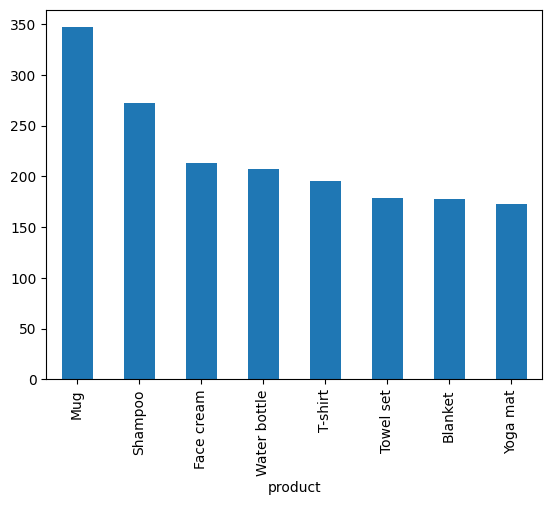

In [ ]:
top_products = df["product"].value_counts().head(8)     # 8 найпопулярніших товарів

top_products.plot(kind="bar")
plt.show()

Що не так: назви товарів довгі, тому повернуті набік і читаються важко; немає заголовка; незрозуміло, що означають числа.

## 📈 2. Горизонтальні стовпчики: `kind="barh"`
Коли підписи довгі, переверніть графік набік. Щоб найбільше значення опинилося **зверху**, відсортуйте дані за зростанням (`sort_values()`), бо `barh` малює стовпчики знизу вгору.

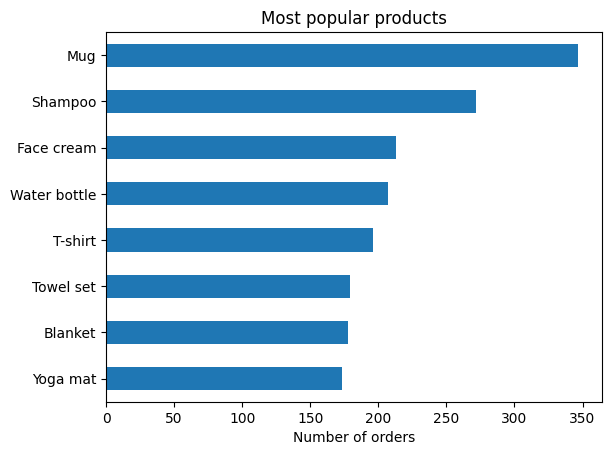

In [ ]:
top_products.sort_values().plot(kind="barh")
plt.title("Most popular products")
plt.xlabel("Number of orders")
plt.ylabel("")
plt.show()

## 📈 3. Розмір і колір

| Параметр | Що змінює | Приклад |
|---|---|---|
| `figsize=(ширина, висота)` | розмір графіка (у дюймах) | `figsize=(8, 4)` |
| `color=` | колір стовпчиків або лінії | `"steelblue"`, `"#2a78d6"` |
| `width=` | товщина стовпчиків (від 0 до 1) | `width=0.7` |

Колір задають назвою англійською (`"steelblue"`, `"gray"`) або кодом на кшталт `"#2a78d6"`. Коди зручно підбирати в Google за запитом «color picker».

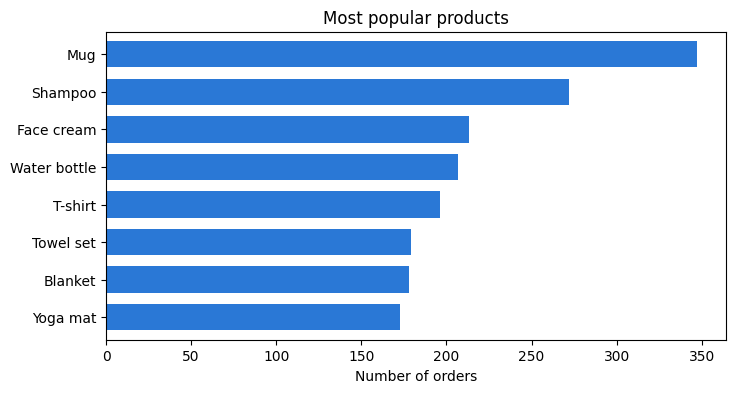

In [ ]:
top_products.sort_values().plot(kind="barh", figsize=(8, 4), color="#2a78d6", width=0.7)
plt.title("Most popular products")
plt.xlabel("Number of orders")
plt.ylabel("")
plt.show()

## 📈 4. Прибираємо зайве: рамка й сітка

Для цього потрібен доступ до самого «полотна» графіка. `.plot()` повертає його, якщо зберегти результат у змінну. Зазвичай її називають **`ax`** (від *axes* — «осі»).

| Команда | Що робить |
|---|---|
| `ax.spines[["top", "right"]].set_visible(False)` | прибирає верхню і праву рамку |
| `ax.grid(axis="x", alpha=0.3)` | ледь помітна сітка вздовж осі X (`alpha` — прозорість) |
| `ax.set_axisbelow(True)` | ховає сітку **під** стовпчики |

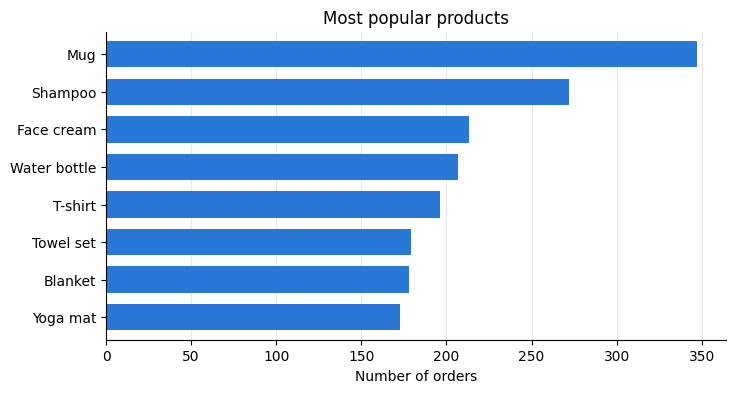

In [ ]:
ax = top_products.sort_values().plot(kind="barh", figsize=(8, 4), color="#2a78d6", width=0.7)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)
plt.title("Most popular products")
plt.xlabel("Number of orders")
plt.ylabel("")
plt.show()

💡 `plt.title("...")` і `ax.set_title("...")` роблять те саме. У курсі ми пишемо `plt.`, а `ax` використовуємо там, де без нього не обійтися.

## 📈 5. Підписи значень
Щоб читач не «вимірював» стовпчики на око, підпишіть кожен його значенням: `ax.bar_label(ax.containers[0])`. Тут `ax.containers[0]` означає «усі стовпчики графіка».

Коли на стовпчиках є підписи, вісь із числами й сітка вже не потрібні.

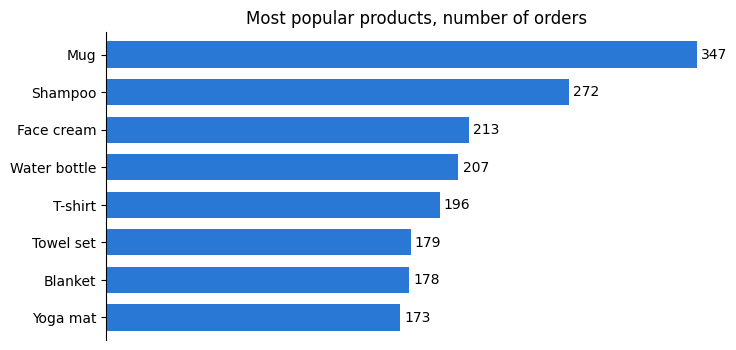

In [ ]:
ax = top_products.sort_values().plot(kind="barh", figsize=(8, 4), color="#2a78d6", width=0.7)
ax.bar_label(ax.containers[0], padding=3)        # padding — відступ підпису від стовпчика
ax.spines[["top", "right", "bottom"]].set_visible(False)
ax.set_xticks([])                                # прибрати числа на осі X: підписи вже є
plt.title("Most popular products, number of orders")
plt.ylabel("")
plt.show()

Порівняйте з першим графіком: дані ті самі, а читати набагато легше.

## 📈 6. Виділяємо головне кольором
Графік має **відповідати на питання**. Якщо питання про один конкретний стовпчик, пофарбуйте його яскраво, а решту сірим. Око одразу знайде потрібне.

Питання: **«Як Львів виглядає на тлі інших міст?»**

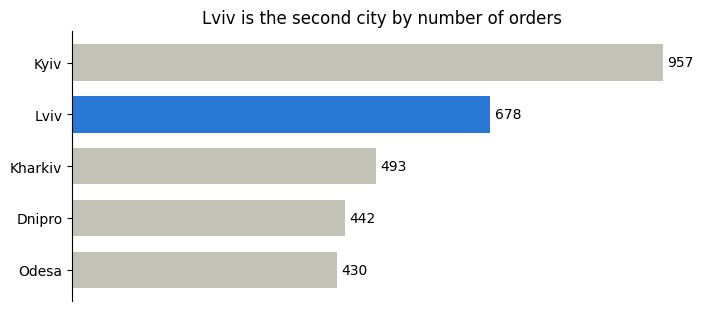

In [ ]:
city_orders = df["city"].value_counts().sort_values()

# Для кожного міста: якщо це Львів — синій, інакше — сірий
colors = ["#2a78d6" if city == "Lviv" else "#c3c2b7" for city in city_orders.index]

ax = city_orders.plot(kind="barh", color=colors, figsize=(8, 3.5), width=0.7)
ax.bar_label(ax.containers[0], padding=3)
ax.spines[["top", "right", "bottom"]].set_visible(False)
ax.set_xticks([])
plt.title("Lviv is the second city by number of orders")
plt.ylabel("")
plt.show()

Рядок `colors = [...]` створює список кольорів, по одному на кожне місто. Читається так: «для кожного `city` зі списку міст візьми синій, якщо це Львів, інакше сірий».

💡 Зверніть увагу на заголовок: він не просто називає графік («Замовлення по містах»), а **формулює висновок**. Так роблять у звітах для керівників.

## 📈 7. Фільтр + графік
Фільтри з цього блокнота добре поєднуються з графіками. Наприклад: що найчастіше **скасовують**?

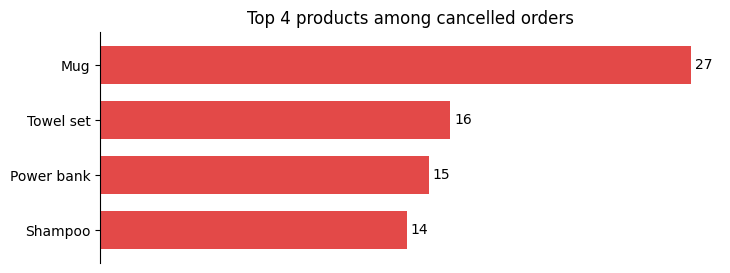

In [ ]:
cancelled = df[df["status"] == "Cancelled"]
cancelled_top = cancelled["product"].value_counts().head(4).sort_values()

ax = cancelled_top.plot(kind="barh", color="#e34948", figsize=(8, 3), width=0.7)
ax.bar_label(ax.containers[0], padding=3)
ax.spines[["top", "right", "bottom"]].set_visible(False)
ax.set_xticks([])
plt.title("Top 4 products among cancelled orders")
plt.ylabel("")
plt.show()

## 📈 8. Один стиль для всіх графіків: `plt.rcParams`

Писати ті самі налаштування в кожному графіку довго. Їх можна задати **один раз**, і вони діятимуть на всі наступні графіки, поки Colab не перезапуститься.

In [ ]:
plt.rcParams.update({
    "figure.figsize": (8, 4),          # розмір за замовчуванням
    "axes.spines.top": False,          # без верхньої рамки
    "axes.spines.right": False,        # без правої рамки
    "axes.grid": True,                 # сітка увімкнена
    "axes.axisbelow": True,            # сітка під стовпчиками
    "grid.alpha": 0.3,                 # сітка ледь помітна
    "lines.linewidth": 2,              # товщі лінії
    "legend.frameon": False,           # легенда без рамки
    # Набір кольорів: перший — для першого ряду даних, другий — для другого і т.д.
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                                         "#e87ba4", "#008300", "#6250d6", "#e34948"]),
})

Тепер навіть найпростіший графік виглядає охайно:

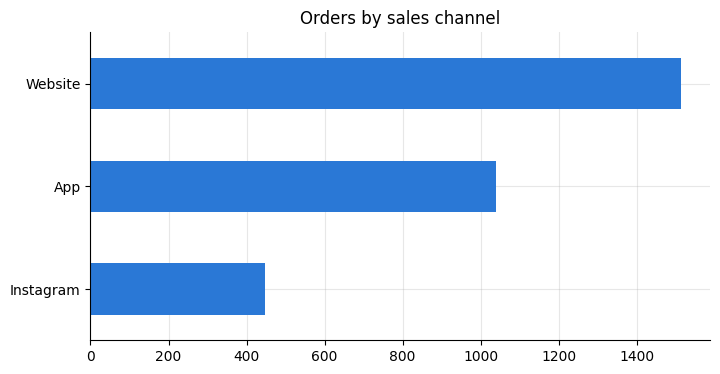

In [ ]:
df["channel"].value_counts().sort_values().plot(kind="barh")
plt.title("Orders by sales channel")
plt.ylabel("")
plt.show()

💡 **У наступних блокнотах** цей стиль уже прописаний у клітинці «📦 Підготовка даних», тож графіки одразу виглядатимуть так.

## 📈 9. Зберегти графік у файл
`plt.savefig()` зберігає графік як картинку для презентації чи листа колегам. Пишіть його **перед** `plt.show()`:
- `dpi=150` — чіткість (чим більше число, тим якісніша картинка);
- `bbox_inches="tight"` — обрізати зайві поля.

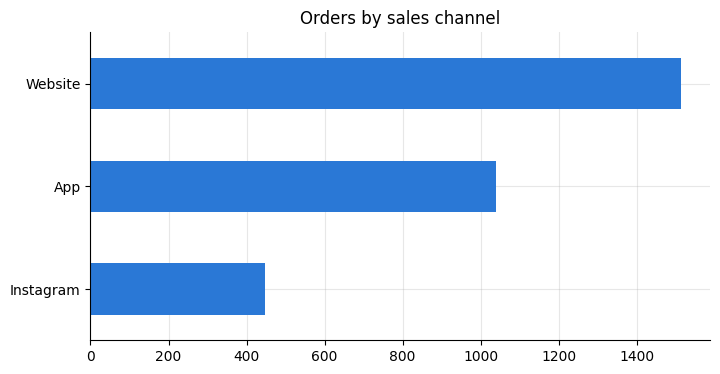

Saved channels.png: look for it in the 📁 panel on the left


In [ ]:
df["channel"].value_counts().sort_values().plot(kind="barh")
plt.title("Orders by sales channel")
plt.ylabel("")
plt.savefig("channels.png", dpi=150, bbox_inches="tight")
plt.show()

print("Saved channels.png: look for it in the 📁 panel on the left")

---
# ✍️ Практика

Відповідайте на запитання «колег». Таблицю `df` не перезаписуйте: результати кладіть у нові змінні.

**Завдання 1.** Покажіть для перших 10 замовлень лише стовпці `order_id`, `product` і `price`.

In [6]:
# Вибираємо три стовпці та перші 10 замовлень
first_10 = df[["order_id", "product", "price"]].head(10)

print(first_10)

   order_id            product  price
0    100001     Dumbbells 5 kg    950
1    100002         Smartwatch   4200
2    100003         Smartwatch   4200
3    100004  Bluetooth speaker   2100
4    100005          Desk lamp   1100
5    100006            Shampoo    260
6    100007            Shampoo    260
7    100008           Yoga mat    700
8    100009          Towel set    650
9    100010            Shampoo    260


**Завдання 2.** Менеджер з логістики питає: скільки замовлень було **скасовано**?

In [7]:
# Знаходимо скасовані замовлення та рахуємо їх кількість
cancelled = df[df["status"] == "Cancelled"]
print(len(cancelled))

205


**Завдання 3.** SMM-менеджер питає: скільки замовлень з **Одеси** прийшло через **Instagram**?

In [ ]:
# Рахуємо замовлення з Одеси, отримані через Instagram

sity_insta = df[(df["city"] == "Odesa") & (df["channel"] == "Instagram")]
print(len(sity_insta))

46


**Завдання 4.** Знайдіть замовлення з категорій **«Електроніка» або «Спорт»**, у яких купили **2 або більше** одиниць товару. Скільки таких замовлень?

In [5]:
# Вибираємо товари категорій Electronics або Sports
# Залишаємо замовлення з кількістю товарів від 2

category_qty = df[(df["category"].isin(["Electronics", "Sports"])) & (df["quantity"] >= 2)]

# Виводимо кількість знайдених замовлень
print(len(category_qty))

273


**Завдання 5.** Відділ якості хоче бачити замовлення з **оцінкою 1 або 2**. Покажіть стовпці `order_id`, `city`, `product`, `status`, `rating`, відсортовані за оцінкою (спочатку 1).

In [ ]:
# Вибираємо замовлення з оцінками 1 або 2 та сортуємо за оцінкою

rating_bad = df[(df["rating"] <= 2)][["order_id", "city", "product", "status", "rating"]].sort_values("rating")
display(rating_bad)

,order_id,city,product,status,rating
28,100029,Lviv,Sneakers,Delivered,1.00
38,100039,Dnipro,Shampoo,Delivered,1.00
100,100101,Lviv,Water bottle,Delivered,1.00
91,100092,Kyiv,Mug,Delivered,1.00
118,100119,Lviv,Bluetooth speaker,Delivered,1.00
...,...,...,...,...,...
2859,102860,Dnipro,Towel set,Delivered,2.00
2960,102961,Kyiv,Face cream,Delivered,2.00
2919,102920,Lviv,Dumbbells 5 kg,Delivered,2.00
2978,102979,Dnipro,Power bank,Delivered,2.00


**Завдання 6 ⭐.** Скільки замовлень з **Києва** у **грудні 2025**, оплачених **накладеним платежем**, було **скасовано**? Які це товари?

In [8]:
# Знаходимо скасовані замовлення з Києва за грудень 2025 з накладеним платежем

count_cancelled = df[
    (df["city"] == "Kyiv") &
    (df["order_date"] >= "2025-12-01") &
    (df["order_date"] < "2026-01-01") &
    (df["payment"] == "Cash on delivery") &
    (df["status"] == "Cancelled")
].copy()

print("Orders found:", len(count_cancelled))

display(count_cancelled[["order_id", "order_date", "product", "price"]])

# Висновок: у грудні 2025 року в Києві було 5 скасованих
# замовлень з оплатою накладеним платежем.

Orders found: 5


,order_id,order_date,product,price
2652,102653,2025-12-05,Towel set,650
2734,102735,2025-12-10,Hoodie,1200
2766,102767,2025-12-12,Hoodie,1200
2875,102876,2025-12-22,Towel set,650
2882,102883,2025-12-23,Headphones,1500


**Завдання 7 📈.** Побудуйте горизонтальний графік **5 найпопулярніших товарів у Дніпрі** (за кількістю замовлень): найбільший зверху, з підписами значень і заголовком.

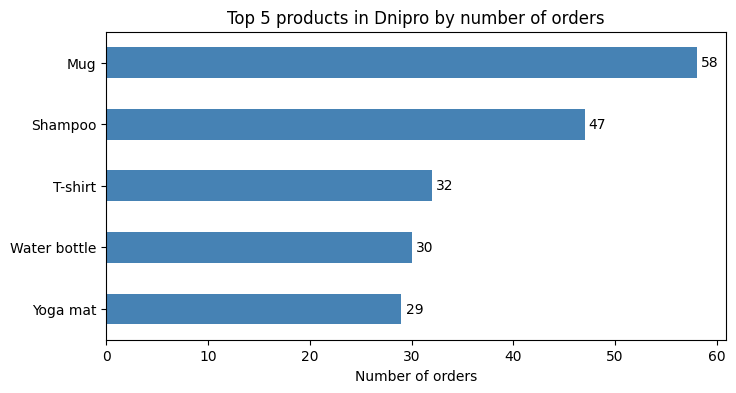

In [4]:
# Створюємо графік п'яти найпопулярніших товарів у Дніпрі
# Вибираємо тільки замовлення з Дніпра
dnipro = df[df["city"] == "Dnipro"]

# Знаходимо 5 найпопулярніших товарів
top_5 = dnipro["product"].value_counts().head(5).sort_values()

# Створюємо горизонтальний графік
ax = top_5.plot(kind="barh", figsize=(8, 4), color="steelblue")

# Додаємо числа біля стовпчиків
ax.bar_label(ax.containers[0], padding=3)

# Додаємо заголовок і назви осей
plt.title("Top 5 products in Dnipro by number of orders")
plt.xlabel("Number of orders")
plt.ylabel("")

# Показуємо графік
plt.show()

**Завдання 8 📈⭐.** Побудуйте графік кількості замовлень по каналах, де канал **`App`** виділено кольором, а решта каналів сірі. Напишіть заголовок-висновок і збережіть графік у файл `my_channel.png`.

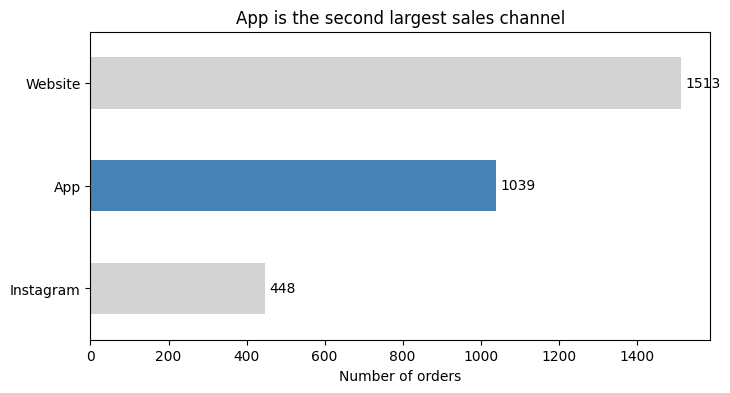

In [9]:
# Створюємо графік замовлень за каналами продажів та виділяємо App

# Рахуємо кількість замовлень для кожного каналу
channel_orders = df["channel"].value_counts().sort_values()

# Створюємо список кольорів
colors = []

for channel in channel_orders.index:
    if channel == "App":
        colors.append("steelblue")
    else:
        colors.append("lightgray")

# Будуємо горизонтальний графік
ax = channel_orders.plot(kind="barh", color=colors, figsize=(8, 4))

# Додаємо числа біля стовпчиків
ax.bar_label(ax.containers[0], padding=3)

# Додаємо заголовок-висновок і підписи
plt.title("App is the second largest sales channel")
plt.xlabel("Number of orders")
plt.ylabel("")

# Зберігаємо графік у PNG
plt.savefig("my_channel.png", dpi=150, bbox_inches="tight")

# Показуємо графік
plt.show()

---
# 📋 Шпаргалка блокнота 2

| Код | Що робить |
|---|---|
| `df["col"]` | один стовпець (Series) |
| `df[["col1", "col2"]]` | кілька стовпців (таблиця) |
| `df.iloc[0:5]` | рядки за позицією (кінець не входить) |
| `df.loc[0:5, ["col"]]` | рядки й стовпці за назвою (кінець входить) |
| `df[df["col"] == x]` | фільтр |
| `(умова1) & (умова2)` / `(умова1) \| (умова2)` | «і» / «або» |
| `df["col"].isin([a, b])` | значення є в списку |
| `df["col"].between(a, b)` | значення в діапазоні |
| `~умова` | «НЕ» |
| `df["col"].str.contains("text")` | текст містить слово |
| `df.loc[умова, ["col1", "col2"]]` | фільтр + стовпці |
| `df.query("col == 'x' and col2 > 5")` | фільтр «словами» |
| `df.sort_values("col", ascending=False)` | сортування |
| `df.nlargest(5, "col")` / `df.nsmallest(5, "col")` | топ-5 найбільших / найменших |
| `df.reset_index(drop=True)` | пронумерувати рядки заново |
| `df[умова].copy()` | незалежна копія вибірки |

**📈 Графіки**

| Код | Що робить |
|---|---|
| `series.sort_values().plot(kind="barh")` | горизонтальні стовпчики, найбільший зверху |
| `figsize=(8, 4)`, `color="#2a78d6"`, `width=0.7` | розмір, колір, товщина стовпчиків |
| `ax = series.plot(...)` | зберегти «полотно» графіка для подальших налаштувань |
| `ax.spines[["top", "right"]].set_visible(False)` | прибрати рамку |
| `ax.grid(axis="x", alpha=0.3)` | ледь помітна сітка |
| `ax.bar_label(ax.containers[0], padding=3)` | підписи значень на стовпчиках |
| `ax.set_xticks([])`, `ax.grid(False)` | прибрати числа на осі / сітку |
| `color=["#2a78d6" if x == "..." else "#c3c2b7" for x in s.index]` | виділити один стовпчик |
| `plt.rcParams.update({...})` | один стиль для всіх графіків |
| `plt.savefig("file.png", dpi=150, bbox_inches="tight")` | зберегти графік (перед `plt.show()`) |

---
### ➡️ Далі: блокнот 3 «Нові стовпці та очищення даних»
Навчимося рахувати нові показники (виручку, категорії замовлень) і приводити до ладу «брудні» дані. А 📈 графіки допоможуть ці дані перевіряти: «до і після», кілька графіків поруч, лінії-орієнтири.

In [ ]:
# @title 💡 Розв'язки практики: відкривайте, лише якщо справді застрягли
# Спершу спробуйте розв'язати кожне завдання самостійно в клітинках «Ваш код тут».

# ---------- Завдання 1 ----------
display(df[["order_id", "product", "price"]].head(10))

# ---------- Завдання 2 ----------
cancelled = df[df["status"] == "Cancelled"]
print("Cancelled orders:", len(cancelled))

# ---------- Завдання 3 ----------
odesa_insta = df[(df["city"] == "Odesa") & (df["channel"] == "Instagram")]
print("Odesa + Instagram:", len(odesa_insta))

# ---------- Завдання 4 ----------
result = df[df["category"].isin(["Electronics", "Sports"]) & (df["quantity"] >= 2)]
print("Orders found:", len(result))
display(result.head())

# ---------- Завдання 5 ----------
bad = df.loc[df["rating"] <= 2, ["order_id", "city", "product", "status", "rating"]]
display(bad.sort_values("rating"))

# ---------- Завдання 6 ⭐ ----------
result = df[
    (df["city"] == "Kyiv")
    & (df["order_date"] >= "2025-12-01")
    & (df["payment"] == "Cash on delivery")
    & (df["status"] == "Cancelled")
]
print("Orders found:", len(result))
display(result[["order_id", "order_date", "product", "price"]])

# ---------- Завдання 7 📈 ----------
dnipro_top = df[df["city"] == "Dnipro"]["product"].value_counts().head(5).sort_values()

ax = dnipro_top.plot(kind="barh", width=0.7)
ax.bar_label(ax.containers[0], padding=3)
ax.set_xticks([])
ax.grid(False)                       # підписи вже є — сітка не потрібна
ax.spines["bottom"].set_visible(False)
plt.title("Top 5 products in Dnipro, number of orders")
plt.ylabel("")
plt.show()

# ---------- Завдання 8 📈⭐ ----------
my_channel = "App"
channel_orders = df["channel"].value_counts().sort_values()
colors = ["#2a78d6" if ch == my_channel else "#c3c2b7" for ch in channel_orders.index]

ax = channel_orders.plot(kind="barh", color=colors, width=0.6, figsize=(8, 3))
ax.bar_label(ax.containers[0], padding=3)
ax.set_xticks([])
ax.grid(False)
ax.spines["bottom"].set_visible(False)
plt.title("App is the second largest sales channel")
plt.ylabel("")
plt.savefig("my_channel.png", dpi=150, bbox_inches="tight")
plt.show()
